# Dark photon-induced magnetic fields in the Earth–ionosphere system: figure reproduction

This notebook reproduces the Figures 2 and 3 of

> **Searching for dark photon dark matter from terrestrial magnetic fields**
> [arXiv:2509.15783](https://arxiv.org/abs/2509.15783) (PRD)

Dark photon dark matter induces an oscillating magnetic field ${\boldsymbol B}_{A'}$ in the cavity between the Earth's surface and the ionosphere. The notebook computes the induced magnetic-field amplitude at the Earth's surface using a multi-step treatment of the atmospheric conductivity profile.

### Structure

| Section | Content |
|---|---|
| **0. Setup** | imports, options (LaTeX, saving PDFs), input data |
| **1. Common modules** | every function used by the figures, defined once |
| **2. Figures** | Figs. 2 and 3; each figure depends only on Sections 0 and 1 |

Run Sections 0 and 1 once, then any figure cell can be run on its own, in any order.

### Requirements

* `numpy`, `scipy` (≥ 1.15, for `scipy.special.sph_harm_y`), `matplotlib`
* A LaTeX installation to typeset labels in the LaTeX style. Without LaTeX, the notebook falls back automatically to matplotlib's built-in mathtext.

---
# 0. Setup

In [1]:
import os
import shutil
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
from scipy.interpolate import interp1d
from scipy.special import spherical_jn, spherical_yn, hankel1, sph_harm_y

In [2]:
# ------------------------------------------------------------------
#  User options
# ------------------------------------------------------------------
FIG_DIR  = "./DarkPhoton_figs"          # output directory for PDF files
SAVE_PDF = False             # True: save every figure as PDF in FIG_DIR

USE_TEX  = None              # True / False, or None = use LaTeX only if it works on this machine

# ------------------------------------------------------------------
def _latex_works():
    """Test-render a label with LaTeX (fails, e.g., if the cm-super fonts are missing)."""
    if shutil.which("latex") is None:
        return False
    try:
        with plt.rc_context({"text.usetex": True}):
            fig = plt.figure()
            fig.text(0.5, 0.5, r"$m_{A'}$ [eV]")
            fig.canvas.draw()
        return True
    except Exception:
        return False
    finally:
        plt.close("all")

if USE_TEX is None:
    USE_TEX = _latex_works()
    if not USE_TEX:
        print("LaTeX is not available: labels are typeset with matplotlib's mathtext instead.")
plt.rcParams["text.usetex"] = USE_TEX
if USE_TEX:
    plt.rcParams["text.latex.preamble"] = r"\usepackage{amsmath}"
BVEC = r"\boldsymbol{B}" if USE_TEX else r"\mathbf{B}"   # bold-face B in axis labels

def save_pdf(fig, filename):
    """Save a figure as PDF in FIG_DIR, if SAVE_PDF is True."""
    if SAVE_PDF:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, filename), bbox_inches="tight")

---
# 1. Common modules

All the physics is in this section. The figure cells in Section 2 only set parameters, call these functions and plot.

| Subsection | Main functions |
|---|---|
| 1.1 Constants and unit conversions | `m2f`, `f2m`, `xx`, `nn2` |
| 1.2 Atmospheric conductivity models | `sigma_kudintseva16`, `sigma_nickolaenko16`, `sigma_galuk18` |
| 1.3 Dark photon-induced magnetic field (multi-step treatment) | `mode_coeff_surface`, `mode_coeff_surface_perfect_cond`, `b2B`, `B2b` |

## 1.1 Constants and unit conversions

In [3]:
R_EARTH = 6371.2     # Earth radius [km]

def m2f(mass):
    """Dark photon mass [eV]  ->  frequency [Hz]."""
    return 0.24 * mass / 1e-15

def f2m(freq):
    """Frequency [Hz]  ->  dark photon mass [eV]."""
    return freq * 1e-15 / 0.24

def xx(r, mass, RE=R_EARTH):
    """Dimensionless radius x = m_{A'} r  (r in km; 0.032 = m_{A'} R_E for m_{A'} = 1e-15 eV)."""
    return 0.032 * (mass / 1e-15) * r / RE

def nn2(sigma, mass):
    """Squared refractive index n^2 = 1 + i sigma/omega for conductivity sigma [S/m]."""
    return 1 + 1j * 0.74 * (sigma / 1e-10) * (1e-14 / mass)

## 1.2 Atmospheric conductivity models

Tabulated conductivity profiles $\sigma(h)$ [S/m] as a function of altitude $h=r-R_{\rm E}$ [km]:

* `sigma_kudintseva16`: Kudintseva, Nickolaenko, Rycroft & Odzimek, Ann. Geophys. 34, 5 (2016). **Default model.**
* `sigma_nickolaenko16`: Nickolaenko, Galuk & Hayakawa, SpringerPlus 5, 108 (2016), median profile. [doi:10.1186/s40064-016-1742-3](https://doi.org/10.1186/s40064-016-1742-3)
* `sigma_galuk18`: Galuk, Nickolaenko & Hayakawa, J. Atmos. Sol.-Terr. Phys. (2018), day and night profiles.

In [4]:
def sigma_kudintseva16():
    """Kudintseva et al. (2016).  Returns (h [km], sigma [S/m]),  h = 0--99 km."""
    h = np.linspace(0, 99, 100)
    sigma = np.array([1.512E-14, 2.160E-14, 4.090E-14, 6.962E-14, 1.049E-13, 1.482E-13, 2.019E-13, 2.712E-13, 3.549E-13, 4.651E-13, 5.943E-13, 7.629E-13, 9.578E-13, 1.209E-12, 1.499E-12, 1.867E-12, 2.285E-12, 2.796E-12, 3.375E-12, 4.093E-12, 4.891E-12, 5.864E-12, 6.930E-12, 8.227E-12, 9.634E-12, 1.135E-11, 1.320E-11,1.545E-11, 1.788E-11, 2.085E-11, 2.416E-11, 2.774E-11, 3.164E-11, 3.626E-11, 4.207E-11, 4.925E-11, 5.762E-11, 6.821E-11, 7.947E-11, 9.359E-11, 1.101E-10, 1.3461E-10, 1.555E-10, 1.840E-10, 2.097E-10, 2.410E-10, 2.651E-10, 2.855E-10, 2.991E-10, 3.183E-10, 3.380E-10, 3.514E-10, 3.710E-10, 3.998E-10, 4.299E-10, 5.229E-10, 6.160E-10, 8.044E-10, 9.929E-10, 1.398E-9, 1.803E-9, 2.731E-9, 3.659E-9, 5.896E-9, 8.133E-9, 1.365E-8, 1.916E-8, 3.249E-8, 4.582E-8, 6.887E-8, 9.636E-8, 1.419E-7, 1.893E-7, 2.839E-7, 4.258E-7, 5.678E-7, 7.570E-7, 9.463E-7, 1.183E-6, 1.467E-6, 1.751E-6, 2.176E-6, 2.602E-6, 3.265E-6, 3.927E-6, 5.157E-6, 6.388E-6, 8.895E-6, 1.145E-5, 1.713E-5, 2.285E-5, 3.686E-5, 5.091E-5, 9.042E-5, 1.230E-4, 2.652E-4, 4.005E-4, 9.690E-4, 1.538E-3, 2.338E-3])
    return h, sigma


def sigma_nickolaenko16():
    """Nickolaenko et al. (2016), median profile.  Returns (h [km], sigma [S/m]),  h = 2--98 km.
       (The day/night profiles in the same reference are not used: they look unreliable.)"""
    h = np.linspace(2, 98, 97)
    log_sigma = np.array([-12.77, -12.68, -12.60, -12.51, -12.43, -12.31, -12.22, -12.08, -11.97, -11.84, -11.74, -11.62, -11.53, -11.42, -11.34, -11.25, -11.17, -11.09, -11.02, -10.94, -10.88, -10.80, -10.74, -10.67, -10.61, -10.55, -10.49, -10.42, -10.37, -10.32, -10.28, -10.24, -10.19, -10.14, -10.09, -10.03, -10.00, -9.95,  -9.92,  -9.86,  -9.83,  -9.78,  -9.75,  -9.70,  -9.67,  -9.64,  -9.62,  -9.59,  -9.56,  -9.52,  -9.48, -9.44, -9.40, -9.30, -9.23, -9.11, -9.02, -8.87, -8.75, -8.57, -8.45, -8.24, -8.10, -7.87, -7.73, -7.50, -7.35, -7.17, -7.02, -6.85, -6.72, -6.55, -6.37, -6.25, -6.12, -6.02, -5.93, -5.83, -5.76, -5.66, -5.58, -5.49, -5.40, -5.29, -5.19, -5.05, -4.94, -4.77, -4.64, -4.43, -4.29, -4.04, -3.89, -3.58, -3.40, -3.01, -2.81])
    return h, 10**log_sigma


def sigma_galuk18():
    """Galuk et al. (2018).  Returns (h [km], sigma_day [S/m], sigma_night [S/m]),  h = 0--110 km."""
    h = np.linspace(0, 110, 111)
    log_sigma_day   = np.array([-14.12, -13.97, -13.82, -13.67, -13.40, -13.17, -12.99, -12.84, -12.71, -12.58, -12.46, -12.35, -12.24, -12.13, -12.03, -11.93, -11.84, -11.74, -11.65, -11.57, -11.48, -11.40, -11.32, -11.24, -11.17, -11.10, -11.03, -10.96, -10.89, -10.82, -10.74, -10.65, -10.58, -10.51, -10.44, -10.35, -10.24, -10.16, -10.09, -9.97,  -9.92,  -9.84,  -9.75, -9.69, -9.63, -9.59, -9.56, -9.53, -9.51, -9.48, -9.46, -9.44, -9.40, -9.38, -9.29, -9.22, -9.10, -9.01, -8.86, -8.75, -8.57, -8.45, -8.24, -8.10, -7.87, -7.73, -7.50, -7.35, -7.17, -7.02, -6.85, -6.72, -6.55, -6.37, -6.25, -6.12, -6.02, -5.93, -5.83, -5.76, -5.66, -5.58, -5.49, -5.41, -5.29, -5.19, -5.05, -4.94, -4.77, -4.64, -4.43, -4.29, -4.04, -3.89, -3.58, -3.40, -3.01, -2.81, -2.61, -2.41, -2.21, -2.00, -1.87, -1.72, -1.48, -1.29, -1.13, -0.96, -0.81, -0.67, -0.54])
    log_sigma_night = np.array([-14.12, -13.97, -13.82, -13.67, -13.40, -13.17, -12.99, -12.84, -12.71, -12.58, -12.46, -12.35, -12.24, -12.13, -12.03, -11.93, -11.84, -11.74, -11.65, -11.57, -11.48, -11.40, -11.32, -11.24, -11.17, -11.10, -11.03, -10.96, -10.89, -10.82, -10.76, -10.69, -10.63, -10.57, -10.51, -10.45, -10.39, -10.32, -10.25, -10.18, -10.11, -10.04, -9.99, -9.93, -9.87, -9.81, -9.75, -9.68, -9.64, -9.62, -9.58, -9.57, -9.56, -9.53, -9.51, -9.48, -9.46, -9.44, -9.40, -9.38, -9.29, -9.22, -9.10, -9.01, -8.86, -8.75, -8.57, -8.45, -8.24, -8.10, -7.90, -7.73, -7.50, -7.35, -7.17, -7.02, -6.85, -6.72, -6.55, -6.37, -6.25, -6.12, -6.02, -5.93, -5.83, -5.76, -5.66, -5.58, -5.49, -5.41, -5.29, -5.19, -5.05, -4.94, -4.77, -4.64, -4.43, -4.29, -4.04, -3.89, -3.58, -3.35, -3.15, -3.05, -2.96, -2.88, -2.81, -2.76, -2.71, -2.67, -2.64])
    return h, 10**log_sigma_day, 10**log_sigma_night


def step_profile(h, sigma, num_step=300):
    """Discretize a tabulated profile into num_step layers (cubic interpolation).
       Returns (h_step, sigma_step), each with num_step+1 points."""
    h_step = np.linspace(h[0], h[-1], num_step + 1)
    return h_step, interp1d(h, sigma, kind="cubic")(h_step)

## 1.3 Dark photon-induced magnetic field (multi-step treatment)

Divide the atmosphere into thin layers, each with a constant conductivity, and construct the radial mode function by matching the solutions across the layer boundaries. Then find the value of the mode function at the Earth's surface and use it to calculate the induced magnetic field there. 

Main functions:

* `mode_coeff_surface(sigma, h, mass)`: mode function $b$ at the Earth's surface
* `mode_coeff_surface_perfect_cond(h_top, mass)`: $b$ for a perfectly conducting ionosphere at height $h_{\rm top}$ (reference curve in Fig. 3)
* `b2B`: convert $b$ to $|{\boldsymbol B}_{A'}|$ at the Earth's surface, as a function of dark photon mass
* `B2b`: convert $|{\boldsymbol B}_{A'}|$ to $b$

All of them take an optional Earth radius `RE` [km]; the default is `R_EARTH`.
The kinetic mixing parameter and the dark-matter density default to $\varepsilon = 10^{-8}$ and $\rho_{\rm DM}=0.3\,{\rm GeV/cm^3}$.


In [5]:
# ---------- Spherical Hankel function of the 1st kind with the factor exp(i x) removed ----------
def spherical_h1n(n, x):
    """h_n^(1)(x) * exp(-i x), from the recurrence relation (any order n)."""
    x = np.asarray(x, dtype=np.complex128)
    h0 = -1j * np.ones_like(x)
    if n == 0:
        return h0
    h1 = -1 - 1j / x
    if n == 1:
        return h1
    hm1, h = h0, h1
    for ell in range(1, n):
        hp1 = (2*ell + 1) / x * h - hm1
        hm1, h = h, hp1
    return h / x

def d_spherical_h1n(l, x):
    """Derivative of h_l^(1)(x) with the factor exp(i x) removed."""
    if l == 0:
        return l * spherical_h1n(l, x) / x - spherical_h1n(l+1, x)
    return spherical_h1n(l-1, x) - (l+1) * spherical_h1n(l, x) / x

sph_h1n  = np.vectorize(spherical_h1n)
dsph_h1n = np.vectorize(d_spherical_h1n)


# ---------- Building blocks of the layer-to-layer connection ----------
def matrix_X(ell, x, n2):
    """Fundamental matrix of (j_ell, y_ell) and their derivatives in a medium of index n^2."""
    sn = np.sqrt(n2)
    x11 = spherical_jn(ell, sn*x)
    x12 = spherical_yn(ell, sn*x)
    x21 = (sn * spherical_jn(ell, sn*x, True) + spherical_jn(ell, sn*x) / x) / n2
    x22 = (sn * spherical_yn(ell, sn*x, True) + spherical_yn(ell, sn*x) / x) / n2
    return np.array([[x11, x12], [x21, x22]], dtype="complex128")

def matrix_X_Xinv(ell, x1, x2, n2):
    """Approximation for matrix_X(ell, x1, n2) @ inverse_matrix_X(ell, x2, n2))  (thin layer)."""
    Xprime11 = 1 + (x1 - x2) * ( -1 / x2 )
    Xprime12 = (x1 - x2) * n2
    Xprime21 = (x1 - x2) * ( ell*(ell+1) / n2 / x2**2 - 1 )
    Xprime22 = 1 + (x1 - x2) * ( -1 / x2 )
    return np.array([[Xprime11, Xprime12], [Xprime21, Xprime22]], dtype='complex128')

def vector_U(n21, n22):
    U1 = 0
    U2 = 2J * np.sqrt( np.pi / 3 ) * (1 / n21 - 1 / n22)
    return np.array([U1, U2], dtype='complex128')


# ---------- Used to impose the boundary condition at the Earth's surface ----------
def vector_W0(ell, x0, n20):
    W0_1 = spherical_jn(ell, np.sqrt(n20) * x0) / n20 / x0 + spherical_jn(ell, np.sqrt(n20) * x0, True) / np.sqrt(n20)
    W0_2 = spherical_yn(ell, np.sqrt(n20) * x0) / n20 / x0 + spherical_yn(ell, np.sqrt(n20) * x0, True) / np.sqrt(n20)
    return np.array([W0_1, W0_2], dtype='complex128')

def V0(n20):
    return -2J * np.sqrt( np.pi / 3 ) * (1 / n20)


# ---------- Used to impose the boundary condition at the uppermost layer ----------
def vector_WN():
    return np.array([1, 1J], dtype='complex128')

def tinvX_WN(ell, xN, n2N):
    """Vector given by transpose_inverse_matrix_X @ vector_WN"""
    tinvX_WN1 = - 1J * np.sqrt(n2N) * xN * spherical_h1n(ell, np.sqrt(n2N) * xN) - 1J * n2N * xN**2 * d_spherical_h1n(ell, np.sqrt(n2N) * xN)
    tinvX_WN2 = 1J * n2N * xN**2 * np.sqrt(n2N) * spherical_h1n(ell, np.sqrt(n2N) * xN)
    return np.array([tinvX_WN1, tinvX_WN2], dtype='complex128')
    

# ---------- Multi-step solver to evaluate the mode function at the Earth's surface ----------
def mode_coeff_surface(sigma, h, mass, RE=R_EARTH, ell=1):
    """Determine the mode coefficients at the Earth's surface by constructing the solution over the layers
       and imposing the boundary conditions."""
    num = sigma.shape[0]
    if num != h.shape[0]:
        raise ValueError("sigma and h must have the same length.")
    #
    n2 = nn2(sigma[0], mass)
    X_invX_series = matrix_X(ell, xx(RE + h[1], mass, RE), n2)
    for i in range(1, num - 1):
        X_invX_series = matrix_X_Xinv(ell, xx(RE + h[i+1], mass, RE), xx(RE + h[i], mass, RE), nn2(sigma[i], mass)) @ X_invX_series
    Z1 = vector_W0(ell, xx(RE, mass, RE), nn2(sigma[0], mass)) 
    Z2 = tinvX_WN(ell, xx(RE + h[num-1], mass, RE), nn2(sigma[num-1], mass)) @ X_invX_series
    matrix_Z = np.array([[Z1[0], Z1[1]], [Z2[0], Z2[1]]], dtype='complex128')
    #
    U_series = vector_U(nn2(sigma[1], mass), nn2(sigma[0], mass))
    for i in range(1, num - 1):
        U_series = (
            vector_U(nn2(sigma[i+1], mass), nn2(sigma[i], mass)) 
            + matrix_X_Xinv(ell, xx(RE + h[i+1], mass, RE), xx(RE + h[i], mass, RE), nn2(sigma[i], mass)) @ U_series
        )
    Y1 = V0(nn2(sigma[0], mass))
    Y2 = tinvX_WN(ell, xx(RE + h[num-1], mass, RE), nn2(sigma[num-1], mass)) @ U_series
    vector_Y = np.array([Y1, Y2], dtype='complex128')
    #
    vector_A_B = np.linalg.inv(matrix_Z) @ vector_Y
    return (
        vector_A_B[0] * spherical_jn(ell, np.sqrt(nn2(sigma[0], mass)) * xx(RE, mass, RE)) 
        + vector_A_B[1] * spherical_yn(ell, np.sqrt(nn2(sigma[0], mass)) * xx(RE, mass, RE))
    )


def mode_coeff_surface_perfect_cond(h_top, mass, RE=R_EARTH, ell=1):
    """b at the Earth's surface for a perfectly conducting ionosphere at altitude h_top [km]
       (vacuum below it)."""
    x0 = xx(RE, mass, RE)
    x1 = xx(RE + h_top, mass, RE)
    detW = (
        (spherical_jn(1, x0) / x0 + spherical_jn(1, x0, True)) * (spherical_yn(1, x1) / x1 + spherical_yn(1, x1, True)) 
        - (spherical_yn(1, x0) / x0 + spherical_yn(1, x0, True)) * (spherical_jn(1, x1) / x1 + spherical_jn(1, x1, True))
    )
    CoeffA = (
        (-2J * np.sqrt( np.pi / 3 )) * (1 / detW) * (spherical_yn(1, x1) / x1 + spherical_yn(1, x1, True) 
                                                    - spherical_yn(1, x0) / x0 - spherical_yn(1, x0, True))
    )
    CoeffB = (
        (-2J * np.sqrt( np.pi / 3 )) * (1 / detW) * (spherical_jn(1, x0) / x0 + spherical_jn(1, x0, True) 
                                                     - spherical_jn(1, x1) / x1 - spherical_jn(1, x1, True))
    )
    return CoeffA * spherical_jn(1, xx(RE, mass, RE)) + CoeffB * spherical_yn(1, xx(RE, mass, RE))


# ---------- Amplitude of the induced magnetic field at the Earth's surface ----------
def b2B(b, epsilon=1e-8, rho_DM=0.3):
    """Convert from the mode function b to the magnetic-field amplitude"""
    return epsilon * np.sqrt(rho_DM) * np.abs(b) * 8.02 * 1E6

def B2b(B, epsilon=1e-8, rho_DM=0.3):
    """Convert from the magnetic-field amplitude to the mode function b"""
    return B / epsilon / np.sqrt(rho_DM) / 8.02 / 1E6

---
# 2. Figures

Each figure has a **compute** cell followed by a **plot** cell; with `SAVE_PDF = True` (currently comment out), the plot cell also writes the PDF. The common parameters ($\varepsilon = 10^{-8}$ and $\rho_{\rm DM}=0.3\,{\rm GeV/cm^3}$, and 300 layers) are the defaults of the functions in Section 1.


## Fig. 2: Magnetic-field amplitude at the Earth's surface vs dark-photon mass

In [6]:
h_step, sigma_step = step_profile(*sigma_kudintseva16(), num_step=300)
mm = np.logspace(-16, -11, 500)                      # dark photon mass [eV]
B_amp = np.array([b2B(mode_coeff_surface(sigma_step, h_step, m, RE=R_EARTH, ell=1)) for m in mm])

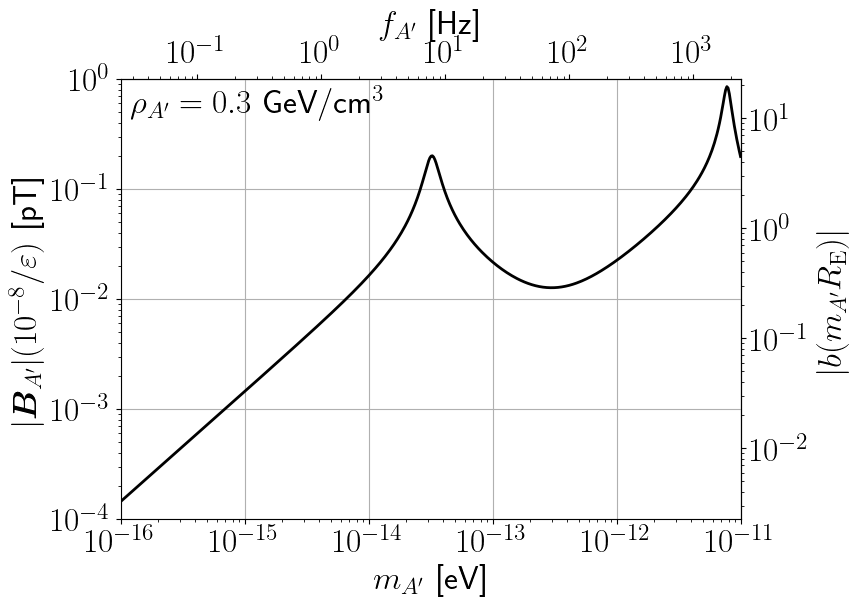

In [7]:
cmap = plt.get_cmap("tab10")
plt.rcParams["font.size"] = 24
fig = plt.figure(figsize=(8, 5.5))
ax = fig.add_subplot(111)
ax.grid()
ax.set_xlim(1E-16, 1E-11)
ax.set_ylim(1E-4, 1E+0)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r"$m_{A'}$ [eV]")
ax.set_ylabel(r"$|\boldsymbol{B}_{A'}| (10^{-8}/\varepsilon)$ [pT]")
ax.text(1.2E-16, 0.5, r"$\rho_{A'} = 0.3~\text{GeV}/\text{cm}^3$",fontsize=24)
ax.plot(mm, B_amp, ls='-', lw=2, color='k')
ax2 = ax.secondary_xaxis('top', functions=(m2f, f2m))
ax2.set_xlabel(r"$f_{A'}$ [Hz]")
ay2 = ax.secondary_yaxis('right', functions=(B2b, b2B))
ay2.set_ylabel(r"$|b(m_{A'} R_{\rm E})|$")
plt.subplots_adjust(left=0.115, right=0.89, bottom=0.1, top=0.9)
plt.show()
#save_pdf(fig, "DarkPhoton_Mode_func_B-field.pdf")

## Fig. 3: Dependence on the conductivity profile

The reference model is Kudintseva et al. It is compared with:
* Galuk et al. (day and night)
* Nickolaenko et al. (median)

The lower panels show the fractional difference from the reference model.

A model with a perfect conductor at an altitude of 80 km and vacuum below is also shown as a gray dashed line.

In [8]:
num_step = 300
h_K,  sig_K          = sigma_kudintseva16()
h_Ni, sig_Ni         = sigma_nickolaenko16()
h_G,  sig_Gd, sig_Gn = sigma_galuk18()
# label -> (h_step, sigma_step, color index of tab10, line style)
models = {
    "Kudintseva et al.: fiducial":     (*step_profile(h_K,  sig_K,  num_step), None, "-"),
    "Galuk et al. (day)":              (*step_profile(h_G,  sig_Gd, num_step), 1, "--"),
    "Galuk et al. (night)":            (*step_profile(h_G,  sig_Gn, num_step), 2, "--"),
    "Nickolaenko et al. (median)":     (*step_profile(h_Ni, sig_Ni, num_step), 3, ":"),
}
REF = "Kudintseva et al.: fiducial"
mm_comp = np.logspace(-16, -11, 500)                      # dark photon mass [eV]
Bamp_comp = {}
for label, (h_step, sigma_step, _, _) in models.items():
    Bamp_comp[label] = np.array([b2B(mode_coeff_surface(sigma_step, h_step, m, RE=R_EARTH, ell=1)) for m in mm_comp])

h_top = 80
Perfect_cond = "vacuum ($h=80$ km)"
Bamp_comp[Perfect_cond] = np.array([b2B(mode_coeff_surface_perfect_cond(h_top, m, RE=R_EARTH, ell=1)) for m in mm_comp])

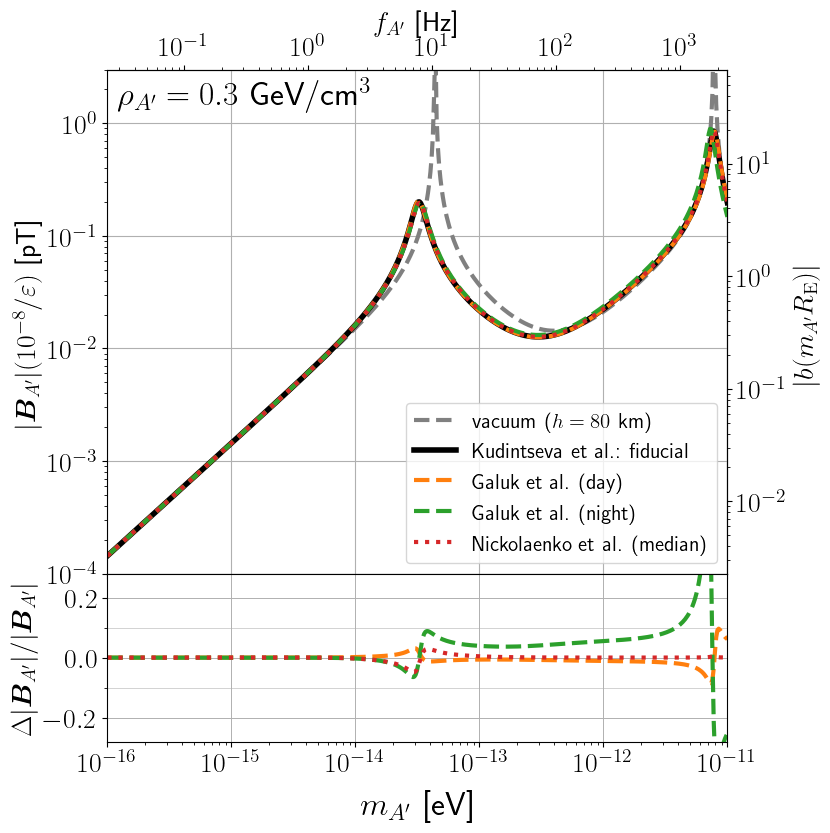

In [9]:
cmap = plt.get_cmap("tab10")
plt.rcParams["font.size"] = 20
fig = plt.figure(figsize=(8, 8))
plt.subplots_adjust(wspace=0, hspace=0)
gs = fig.add_gridspec(2, 1, height_ratios=[3, 1])

ax = fig.add_subplot(gs[0])
ax.grid()
ax.set_xlim(1E-16, 1E-11)
ax.set_ylim(1E-4, 3E+0)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r"$m_{A'}$ [eV]")
ax.set_ylabel(r"$|\boldsymbol{B}_{A'}| (10^{-8}/\varepsilon)$ [pT]")
ax.text(1.2E-16, 1.5, r"$\rho_{A'} = 0.3~\text{GeV}/\text{cm}^3$",fontsize=24)
ax.plot(mm_comp, Bamp_comp[Perfect_cond], ls='--', lw=3, color='gray', label=Perfect_cond)
for label, (_, _, c, ls) in models.items():
    if label == REF:
        ax.plot(mm_comp, Bamp_comp[label], color='k', lw=4, ls=ls, label=label)
    else:
        ax.plot(mm_comp, Bamp_comp[label], color=cmap(c), lw=3, ls=ls, label=label)
ax2 = ax.secondary_xaxis('top', functions=(m2f, f2m))
ax2.set_xlabel(r"$f_{A'}$ [Hz]")
ay2 = ax.secondary_yaxis('right', functions=(B2b, b2B))
ay2.set_ylabel(r"$|b(m_{A'} R_{\rm E})|$")
ax.legend(loc = 'lower right', fontsize = 15)
ax.tick_params(labelbottom=False, labelleft=True, labelright=False, labeltop=False)

bx = fig.add_subplot(gs[1])
#bx.grid()
bx.set_xlim(1E-16, 1E-11)
bx.set_ylim(-0.28, 0.28)
bx.set_xlabel(r"$m_{A'}$ [eV]", size=24, labelpad=10)
bx.set_ylabel(r"$\Delta |\boldsymbol{B}_{A'}| / |\boldsymbol{B}_{A'}|$")
for label, (_, _, c, ls) in models.items():
    if label != REF:
        bx.plot(mm_comp, np.abs(Bamp_comp[label])/np.abs(Bamp_comp[REF]) - 1, color=cmap(c), lw=3, ls=ls)
bx.set_xscale('log')
bx.set_yscale('linear')
bx.grid(which='major', lw=0.7) 
bx.yaxis.set_minor_locator(ticker.AutoMinorLocator(2))
bx.grid(which='minor', lw=0.4, axis='y') 
bx.tick_params(labelbottom=True, labelleft=True, labelright=False, labeltop=False)

plt.subplots_adjust(left=0.115, right=0.89, bottom=0.08, top=0.92)
plt.show()
#save_pdf(fig, "DarkPhoton_B-field_model_dependence.pdf")